# Niedouczenie i przeuczenie

**Plan notatnika:**
1. Dwa sposoby, w jakie model może zawieść
2. Dane do eksperymentów
3. Punkt odniesienia (baseline)
4. Niedouczenie
5. Przeuczenie
6. Krzywa złożoności – jak znaleźć „złoty środek”
7. Naprawa niedouczenia modelu liniowego
8. Czy więcej danych pomoże? Krzywa uczenia
9. Ograniczanie złożoności (regularyzacja) i zespoły modeli
10. Podsumowanie

## 1. Dwa sposoby, w jakie model może zawieść

Celem modelu nie jest zapamiętanie danych treningowych, lecz **dobre przewidywanie na nowych danych** (generalizacja). Model może zawieść na dwa sposoby:

- **Niedouczenie (underfitting)** – model jest zbyt prosty, by uchwycić zależność w danych. Wypada słabo **zarówno na zbiorze treningowym, jak i testowym**.
- **Przeuczenie (overfitting)** – model jest zbyt złożony i uczy się także szumu oraz przypadkowych szczegółów danych treningowych. Wypada **bardzo dobrze na treningowym, a wyraźnie gorzej na testowym**.

Diagnozę stawiamy, porównując wynik na zbiorze treningowym i testowym (oraz z modelem bazowym):

| Wynik treningowy | Wynik testowy | Diagnoza |
|---|---|---|
| niski | niski (podobny) | niedouczenie |
| wysoki | wyraźnie niższy | przeuczenie |
| wysoki | wysoki (podobny) | model dobrze dopasowany |

To ta sama zależność, którą widzieliśmy jako kompromis **obciążenia i wariancji** (rozdział 2.3): prosty model ma duże obciążenie (błędne założenia), złożony – dużą wariancję (zbytnia wrażliwość na dane treningowe).

### Co robić?

| Problem | Typowe działania |
|---|---|
| Niedouczenie | bardziej złożony model, lepsze cechy (feature engineering), słabsza regularyzacja |
| Przeuczenie | prostszy model (np. mniejsza głębokość drzewa), regularyzacja (L1, L2), więcej danych, walidacja krzyżowa do doboru hiperparametrów, uśrednianie wielu modeli (lasy losowe), early stopping i dropout w sieciach neuronowych (rozdział 5) |

W tym notatniku pokażemy większość tych działań na jednym, prostym zbiorze.

## 2. Dane do eksperymentów

Użyjemy `make_moons` – dwóch „księżyców”, których **nie da się rozdzielić linią prostą**. Parametr `noise` dodaje szum, więc klasy częściowo się nakładają i żaden model nie osiągnie 100% na nowych danych.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split, validation_curve, learning_curve
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline

np.random.seed(42)

Bad value in file PosixPath('/Users/tomasz/.matplotlib/stylelib/company.mplstyle'), line 3 ("axes.prop_cycle: cycler('color', ['#123D98', '#C21E3C', '#E2A713', '#00AEEF', '#7F3F98'])"): Key axes.prop_cycle: "cycler('color', ['" is not a valid cycler construction: Could not parse "cycler('color', ['": unterminated string literal (detected at line 1) (<unknown>, line 1)
Bad value in file PosixPath('/Users/tomasz/.matplotlib/stylelib/company.mplstyle'), line 6 ('grid.color: #e0e0e0'): Key grid.color: '' does not look like a color arg


Zbiór treningowy: (1400, 2), testowy: (600, 2)


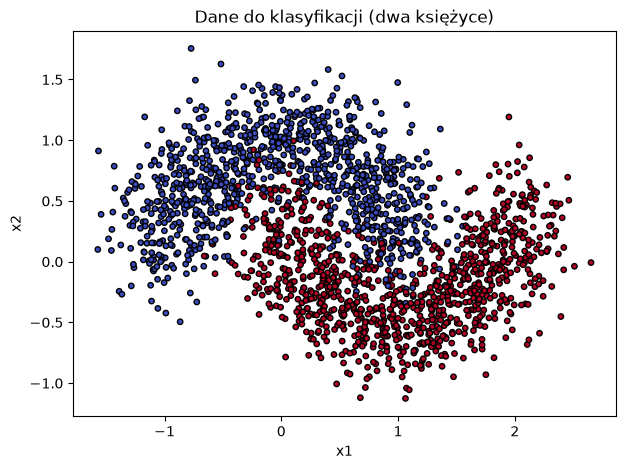

In [2]:
X, y = make_moons(n_samples=2000, noise=0.25, random_state=42)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y)

print(f'Zbiór treningowy: {X_train.shape}, testowy: {X_test.shape}')

plt.figure(figsize=(7, 5))
plt.scatter(X[:, 0], X[:, 1], c=y, cmap='coolwarm', edgecolor='k', s=15)
plt.title('Dane do klasyfikacji (dwa księżyce)')
plt.xlabel('x1')
plt.ylabel('x2')
plt.show()

Przygotujmy dwie funkcje pomocnicze: `ocen` uczy model i zapisuje jego dokładność (accuracy) na zbiorze treningowym i testowym, a `pokaz_model` dodatkowo rysuje **granicę decyzyjną** (obszary, w których model przewiduje daną klasę).

In [3]:
wyniki = {}


def ocen(model, nazwa):
    # Uczy model i zapisuje accuracy na zbiorze treningowym i testowym.
    model.fit(X_train, y_train)
    wyniki[nazwa] = {'train': model.score(X_train, y_train),
                     'test': model.score(X_test, y_test)}
    return model


def pokaz_model(model, nazwa):
    # Uczy model i rysuje granicę decyzyjną na zbiorze treningowym i testowym.
    ocen(model, nazwa)
    fig, osie = plt.subplots(1, 2, figsize=(12, 4.5))
    zbiory = [('treningowy', X_train, y_train), ('testowy', X_test, y_test)]
    for ax, (opis, X_z, y_z) in zip(osie, zbiory):
        DecisionBoundaryDisplay.from_estimator(
            model, X_z, ax=ax, response_method='predict', cmap='coolwarm', alpha=0.3)
        ax.scatter(X_z[:, 0], X_z[:, 1], c=y_z, cmap='coolwarm', edgecolor='k', s=15)
        ax.set_title(f'Zbiór {opis}: accuracy {model.score(X_z, y_z):.3f}')
    fig.suptitle(nazwa)
    plt.tight_layout()
    plt.show()

## 3. Punkt odniesienia (baseline)

Zanim ocenimy model, sprawdźmy, ile daje „model”, który nie uczy się niczego (zawsze przewiduje najczęstszą klasę). Klasy są zrównoważone, więc spodziewamy się ok. 50%.

In [4]:
ocen(DummyClassifier(strategy='most_frequent'), 'baseline (najczęstsza klasa)')
wyniki

{'baseline (najczęstsza klasa)': {'train': 0.5, 'test': 0.5}}

## 4. Niedouczenie

**Regresja logistyczna** tworzy granicę w postaci **linii prostej**, a nasze klasy mają kształt księżyców.

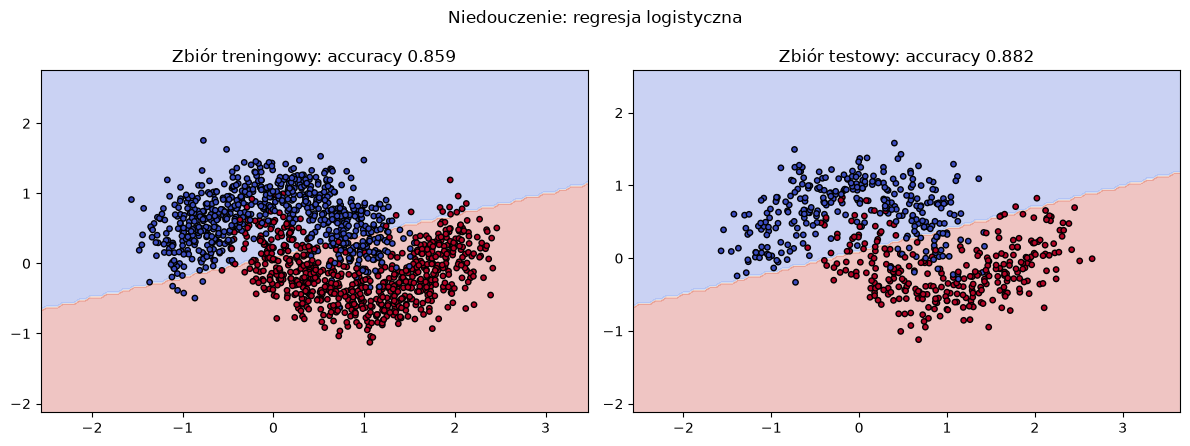

In [5]:
pokaz_model(LogisticRegression(), 'Niedouczenie: regresja logistyczna')

Wynik na zbiorze treningowym i testowym jest **podobny i umiarkowany** – model jest za prosty, więc nie radzi sobie nawet na danych, które „widział”. Zauważmy, że wynik jest wyraźnie lepszy od baseline, ale dla tego problemu zdecydowanie można zrobić więcej.

Podobny efekt daje **drzewo o głębokości 1** (pojedynczy podział, tzw. *pniak* – ang. *decision stump*):

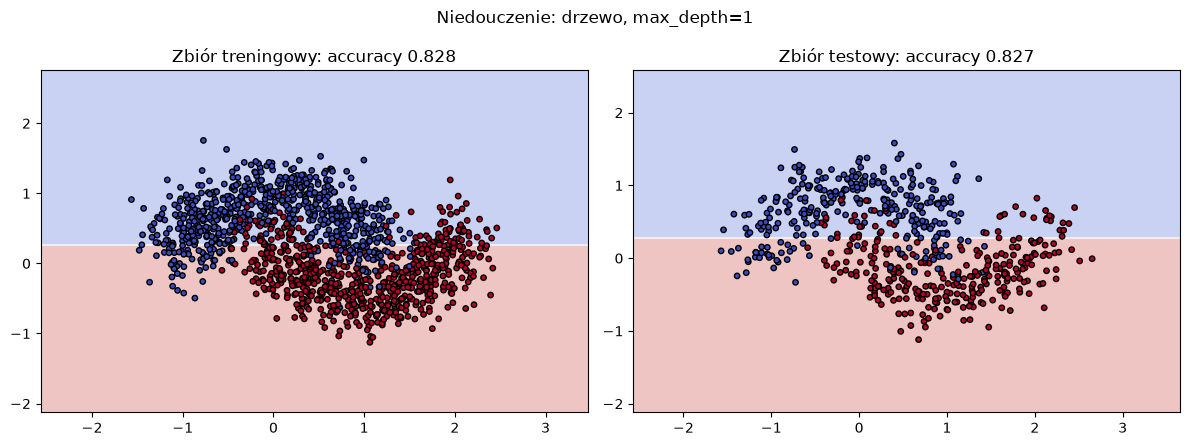

In [6]:
pokaz_model(DecisionTreeClassifier(max_depth=1, random_state=42),
            'Niedouczenie: drzewo, max_depth=1')

## 5. Przeuczenie

Drzewo bez ograniczenia głębokości będzie dzielić dane tak długo, aż każdy liść zawiera obserwacje jednej klasy – czyli **zapamięta zbiór treningowy**, łącznie z szumem.

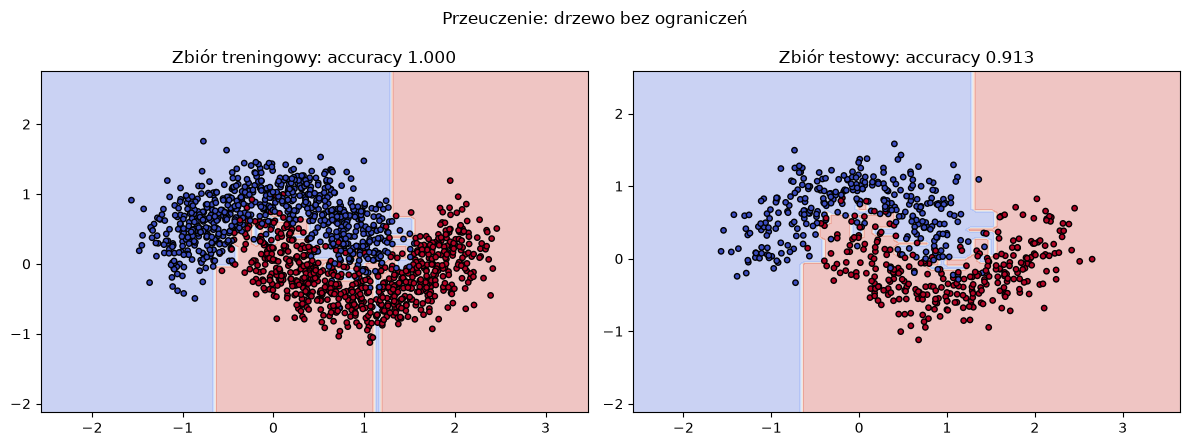

Głębokość drzewa: 16, liczba liści: 98


In [7]:
drzewo_pelne = DecisionTreeClassifier(random_state=42)
pokaz_model(drzewo_pelne, 'Przeuczenie: drzewo bez ograniczeń')

print(f'Głębokość drzewa: {drzewo_pelne.get_depth()}, liczba liści: {drzewo_pelne.get_n_leaves()}')

Na zbiorze treningowym model osiąga **100%**, ale na testowym wynik jest wyraźnie niższy. Granica decyzyjna jest nierówna – wokół pojedynczych punktów szumu powstają wąskie „wysepki” i paski innej klasy. Różnica między wynikiem treningowym a testowym (tzw. **luka generalizacji**) jest typowym objawem przeuczenia.

> Pamiętajmy: wynik na zbiorze treningowym **nie mówi nic** o jakości modelu na nowych danych. Zawsze oceniamy na danych, których model nie widział.

## 6. Krzywa złożoności – jak znaleźć „złoty środek”

Złożonością drzewa steruje głównie `max_depth`. Sprawdźmy, jak zmieniają się wyniki dla głębokości od 1 do 20. Funkcja `validation_curve` dla każdej wartości hiperparametru liczy wynik na zbiorze treningowym i **w walidacji krzyżowej** (dane treningowe są dzielone na 5 części, a model jest oceniany na części nieużytej do uczenia; więcej w rozdziale 4.4).

Do wyboru hiperparametru używamy walidacji na danych treningowych – **zbiór testowy zostawiamy do jednej, końcowej oceny**.

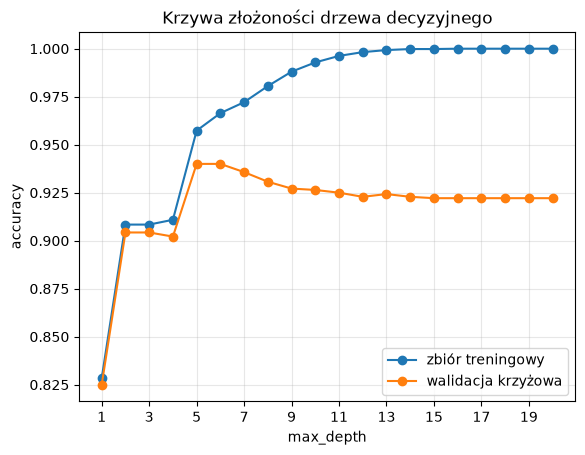

Najlepsza głębokość wg walidacji krzyżowej: 5 (accuracy 0.940)


In [8]:
glebokosci = np.arange(1, 21)

wynik_train, wynik_cv = validation_curve(
    DecisionTreeClassifier(random_state=42), X_train, y_train,
    param_name='max_depth', param_range=glebokosci, cv=5)

srednia_train = wynik_train.mean(axis=1)
srednia_cv = wynik_cv.mean(axis=1)

plt.plot(glebokosci, srednia_train, 'o-', label='zbiór treningowy')
plt.plot(glebokosci, srednia_cv, 'o-', label='walidacja krzyżowa')
plt.xlabel('max_depth')
plt.ylabel('accuracy')
plt.title('Krzywa złożoności drzewa decyzyjnego')
plt.xticks(glebokosci[::2])
plt.legend()
plt.grid(alpha=0.3)
plt.show()

najlepsza_glebokosc = int(glebokosci[srednia_cv.argmax()])
print(f'Najlepsza głębokość wg walidacji krzyżowej: {najlepsza_glebokosc} '
      f'(accuracy {srednia_cv.max():.3f})')

Krzywe opisują typowy przebieg:

- **mała głębokość** – oba wyniki niskie (niedouczenie),
- **wzrost głębokości** – wynik treningowy rośnie niemal do 100%, a wynik walidacyjny najpierw rośnie, potem **przestaje rosnąć i lekko spada** (przeuczenie),
- **największy wynik walidacyjny** wskazuje rozsądną złożoność modelu.

Im większa **luka** między krzywymi, tym silniejsze przeuczenie. Sprawdźmy wybrany model:

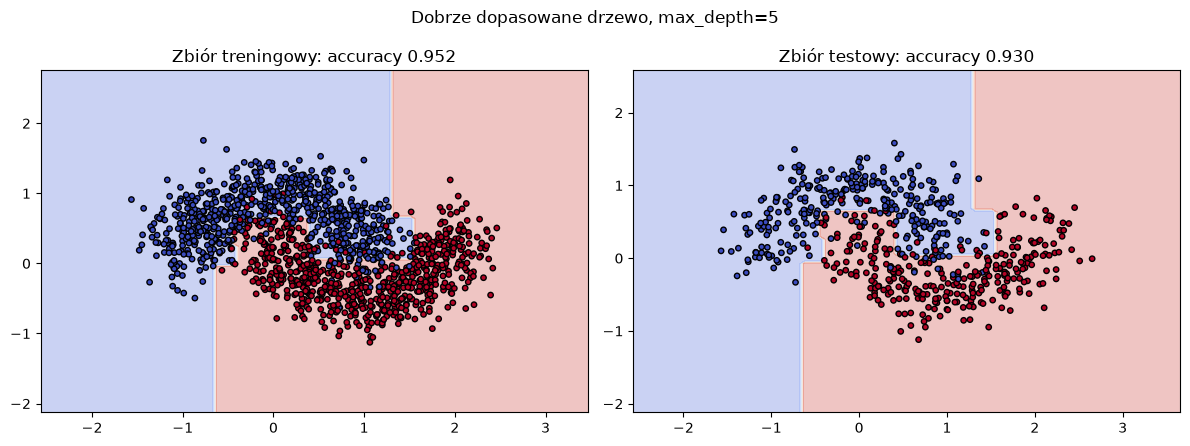

In [9]:
pokaz_model(DecisionTreeClassifier(max_depth=najlepsza_glebokosc, random_state=42),
            f'Dobrze dopasowane drzewo, max_depth={najlepsza_glebokosc}')

Granica jest gładsza i dobrze odwzorowuje kształt księżyców, a wynik testowy jest wyższy niż dla drzewa bez ograniczeń, przy znacznie mniejszej luce między zbiorem treningowym a testowym.

## 7. Naprawa niedouczenia modelu liniowego

Regresja logistyczna była za prosta, ale **nie musimy zmieniać modelu**. Możemy dodać cechy, które pozwolą jej „zakrzywić” granicę – np. kwadraty i iloczyny cech (`PolynomialFeatures`, jak w regresji wielomianowej z rozdziału 3.1). To przykład **feature engineeringu** jako remedium na niedouczenie.

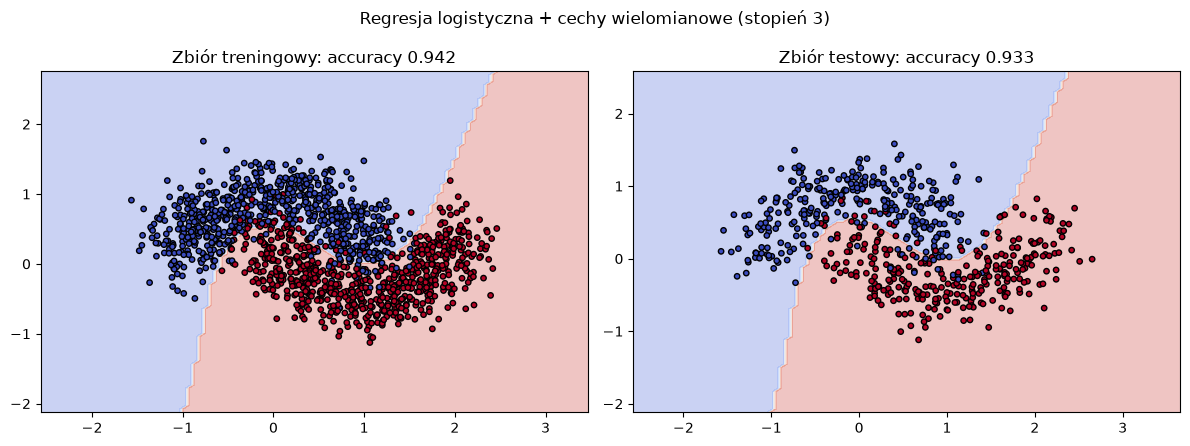

In [10]:
model_wielomianowy = make_pipeline(PolynomialFeatures(degree=3, include_bias=False),
                                   LogisticRegression(max_iter=1000))
pokaz_model(model_wielomianowy, 'Regresja logistyczna + cechy wielomianowe (stopień 3)')

Ten sam algorytm, ale z lepszymi cechami, daje teraz wynik porównywalny z najlepszym drzewem. Zbyt wysoki stopień wielomianu doprowadziłby jednak do przeuczenia, tak jak w regresji wielomianowej – stopień jest hiperparametrem, który dobieramy walidacją.

## 8. Czy więcej danych pomoże? Krzywa uczenia

Przeuczenie wynika częściowo z tego, że danych jest za mało w stosunku do złożoności modelu. **Krzywa uczenia** pokazuje wyniki w zależności od liczby obserwacji treningowych. Porównamy drzewo bez ograniczeń i drzewo o dobranej głębokości.

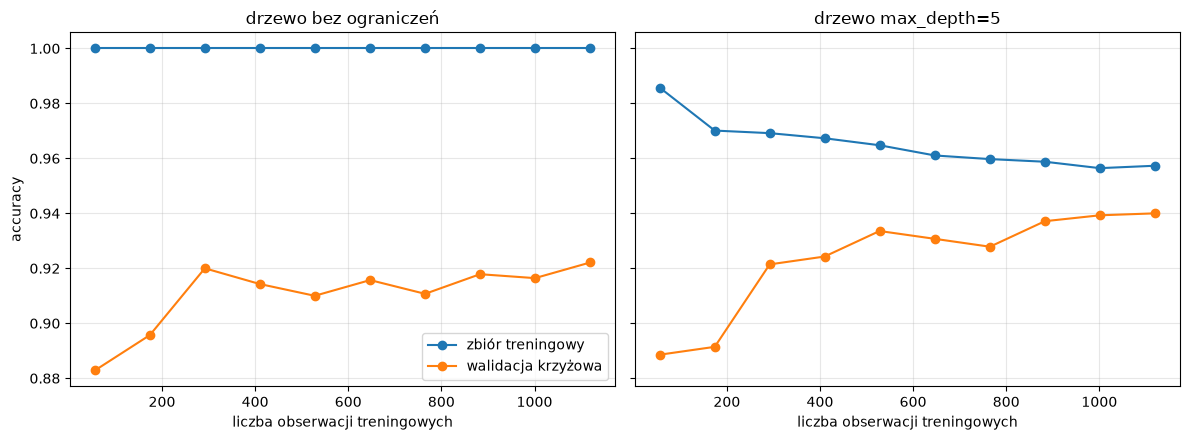

In [11]:
modele = {
    'drzewo bez ograniczeń': DecisionTreeClassifier(random_state=42),
    f'drzewo max_depth={najlepsza_glebokosc}': DecisionTreeClassifier(
        max_depth=najlepsza_glebokosc, random_state=42),
}

fig, osie = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, (nazwa, model) in zip(osie, modele.items()):
    rozmiary, wynik_train, wynik_cv = learning_curve(
        model, X_train, y_train, train_sizes=np.linspace(0.05, 1.0, 10),
        cv=5, shuffle=True, random_state=42)
    ax.plot(rozmiary, wynik_train.mean(axis=1), 'o-', label='zbiór treningowy')
    ax.plot(rozmiary, wynik_cv.mean(axis=1), 'o-', label='walidacja krzyżowa')
    ax.set_title(nazwa)
    ax.set_xlabel('liczba obserwacji treningowych')
    ax.grid(alpha=0.3)
osie[0].set_ylabel('accuracy')
osie[0].legend()
plt.tight_layout()
plt.show()

Obserwacje:

- **Drzewo bez ograniczeń** ma zawsze ok. 100% na treningowym, a wynik walidacyjny rośnie wraz z liczbą danych – luka zmniejsza się, ale pozostaje duża. Więcej danych **pomaga**, lecz nie rozwiązuje problemu.
- **Drzewo z ograniczoną głębokością** ma wyraźnie mniejszą lukę, która dodatkowo maleje wraz z liczbą danych: wynik walidacyjny rośnie i zbliża się do treningowego. Gdy krzywe się zbiegną, dalsze zbieranie danych **niewiele da** – trzeba wtedy poprawić model lub cechy.

Krzywa uczenia pomaga więc zdecydować, czy opłaca się zbierać więcej danych, czy zmienić model.

## 9. Ograniczanie złożoności i zespoły modeli

Przeuczenie drzewa można ograniczać na kilka sposobów (to **regularyzacja** drzewa):

- `max_depth` – maksymalna głębokość,
- `min_samples_leaf` – minimalna liczba obserwacji w liściu (wymusza gładszą granicę),
- `min_samples_split`, `max_leaf_nodes` – inne ograniczenia podziałów.

Innym podejściem jest **uśrednianie wielu drzew** (las losowy, rozdział 4.2), które zmniejsza wariancję pojedynczego drzewa. Porównajmy te opcje:

In [12]:
ocen(DecisionTreeClassifier(min_samples_leaf=20, random_state=42), 'drzewo min_samples_leaf=20')
ocen(RandomForestClassifier(n_estimators=200, random_state=42), 'las losowy (200 drzew)')

tabela = pd.DataFrame(wyniki).T
tabela['luka (train - test)'] = tabela['train'] - tabela['test']
tabela.round(3)

,train,test,luka (train - test)
baseline (najczęstsza klasa),0.500,0.500,0.000
Niedouczenie: regresja logistyczna,0.859,0.882,-0.022
"Niedouczenie: drzewo, max_depth=1",0.828,0.827,0.001
Przeuczenie: drzewo bez ograniczeń,1.000,0.913,0.087
"Dobrze dopasowane drzewo, max_depth=5",0.952,0.930,0.022
Regresja logistyczna + cechy wielomianowe (stopień 3),0.942,0.933,0.009
drzewo min_samples_leaf=20,0.949,0.935,0.014
las losowy (200 drzew),1.000,0.943,0.057


- Drzewo bez ograniczeń ma największą lukę (przeuczenie), a modele niedouczone – niskie wyniki obu zbiorów.
- Ograniczenie głębokości lub liczby obserwacji w liściu **zmniejsza lukę** i poprawia wynik testowy.
- Las losowy ma na treningowym nadal ok. 100% (jego drzewa nie są ograniczane), ale na testowym wypada najlepiej ze wszystkich modeli – uśrednianie ogranicza skutki przeuczenia pojedynczych drzew.
- Pamiętajmy, że różnice rzędu 1 punktu procentowego mieszczą się w granicach losowości jednego podziału na zbiór treningowy i testowy.

## 10. Podsumowanie

1. **Niedouczenie** = słaby wynik na treningowym i testowym; **przeuczenie** = bardzo dobry na treningowym, wyraźnie gorszy na testowym.
2. Diagnozę stawiamy, porównując wyniki **treningowy, testowy i baseline**.
3. Złożoność modelu dobieramy **krzywą złożoności** (walidacja krzyżowa), a nie na zbiorze testowym.
4. Niedouczenie leczymy **lepszymi cechami lub bardziej złożonym modelem**, przeuczenie – **ograniczeniem złożoności, regularyzacją, większą ilością danych lub uśrednianiem modeli**.
5. **Krzywa uczenia** pokazuje, czy więcej danych ma sens.